# LLM Performance on Labeled Data

This notebook analyzes the performance of all LLM models (8B and 70B, zero-shot, few-shot, and frame-guided) compared to human annotations on the **labeled dataset** (2,077 texts).

**Focus**: Primary label (conspiracy) and secondary labels (span annotations)

## Models Analyzed:
1. **Llama-3-8B-Instruct Zero-Shot** (`8b_zero`)
2. **Llama-3-8B-Instruct Few-Shot** (`8b_few`)
3. **Llama-3-8B-Instruct Frame-Guided** (`8b_frame`)
4. **Llama-3.3-70B-Instruct Zero-Shot** (`70b_zero`)
5. **Llama-3.3-70B-Instruct Few-Shot** (`70b_few`)
6. **Llama-3.3-70B-Instruct Frame-Guided** (`70b_frame`)

## Analysis Sections:
1. **Data Loading** - Load all model outputs and human annotations
2. **Overall Performance Metrics** - Accuracy, Precision, Recall, F1 for conspiracy classification
3. **Confusion Matrices** - Visual comparison of conspiracy classification performance
4. **Label Distribution** - Compare how models distribute conspiracy predictions vs human
5. **Span Annotation Quality** - Compare span extraction across models (secondary labels)
6. **Error Analysis** - Examine disagreement patterns
7. **Model Ranking** - Identify best-performing models
8. **Key Insights** - Summary and recommendations


In [1]:
# Setup & Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (
    confusion_matrix, 
    precision_recall_fscore_support, 
    accuracy_score,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
import warnings
warnings.filterwarnings('ignore')

# Set paths
BASE = Path('/home/ashrafs/projects/Conspiracy-Proj')
DATA = BASE / 'Data'
OUT = BASE / 'outputs'

# Set plotting style
sns.set_theme(context="notebook", style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10
%matplotlib inline

print("✓ Setup complete!")
print(f"Data directory: {DATA}")
print(f"Output directory: {OUT}")


✓ Setup complete!
Data directory: /home/ashrafs/projects/Conspiracy-Proj/Data
Output directory: /home/ashrafs/projects/Conspiracy-Proj/outputs


In [2]:
# Load Human Annotations (Ground Truth)
print("Loading human annotations...")

# Human classifications
human_class_path = DATA / 'all_classifications.csv'
if not human_class_path.exists():
    raise FileNotFoundError(f"Human classification file not found: {human_class_path}")

human_class = pd.read_csv(human_class_path)
print(f"Loaded human classifications: {len(human_class):,} rows")

# Normalize booleans
BOOL_MAP = {'true': True, 'false': False, 'yes': True, 'no': False, 'y': True, 'n': False, '1': True, '0': False}
def parse_bool(s: pd.Series) -> pd.Series:
    v = s.astype(str).str.strip().str.lower().map(BOOL_MAP)
    unmapped = v.isna()
    if unmapped.any():
        num = pd.to_numeric(s[unmapped], errors='coerce')
        v.loc[unmapped & num.notna()] = (num[num.notna()] > 0).astype(bool)
    return v

# Create majority-vote aggregation
hc = human_class.copy()
hc['conspiracy_mv'] = parse_bool(hc['conspiracy'])
hc['supportive_mv'] = parse_bool(hc['supportive'])

grp = hc.groupby('text_id', as_index=False)
agg = grp.agg(
    conspiracy_mv=('conspiracy_mv', lambda x: bool(np.mean(x.dropna()) >= 0.5) if len(x.dropna()) else np.nan),
    supportive_mv=('supportive_mv', lambda x: bool(np.mean(x.dropna()) >= 0.5) if len(x.dropna()) else np.nan),
)

if 'annotator_id' in hc.columns:
    n_anns = grp['annotator_id'].nunique().rename(columns={'annotator_id':'n_annotators'})
    agg = agg.merge(n_anns, on='text_id', how='left')
else:
    sizes = grp.size().rename(columns={0:'n_annotators'})
    agg = agg.merge(sizes, on='text_id', how='left')

print(f"Human majority-vote rows: {len(agg):,}")
print(f"  - Conspiratorial: {agg['conspiracy_mv'].sum():,} ({agg['conspiracy_mv'].mean():.1%})")

# Load human spans
human_span_path = DATA / 'all_span_annotations.csv'
human_spans = None
if human_span_path.exists():
    human_spans = pd.read_csv(human_span_path)
    print(f"\nLoaded human spans: {len(human_spans):,} rows")
    SPAN_COLS = ['out-group','plan','call-to-action','in-group','secret']
    available_spans = [c for c in SPAN_COLS if c in human_spans.columns]
    print(f"  - Available span categories: {available_spans}")
else:
    print(f"\n⚠ Human span file not found: {human_span_path}")

print("\n✓ Human data loaded successfully!")


Loading human annotations...
Loaded human classifications: 3,243 rows
Human majority-vote rows: 2,077
  - Conspiratorial: 543 (26.6%)

Loaded human spans: 934 rows
  - Available span categories: ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']

✓ Human data loaded successfully!


In [3]:
# Load All Model Outputs
print("Loading model outputs...\n")

# Model classification outputs (human-schema CSVs)
model_files = {
    '8b_zero': OUT / 'llama8b-zeroshot_all_classifications.csv',
    '8b_few': OUT / 'llama8b-fewshot_all_classifications.csv',
    '8b_frame': OUT / 'llama8b-frame_all_classifications.csv',
    '70b_zero': OUT / 'llama-3.3-70B-zeroshot_all_classifications.csv',
    '70b_few': OUT / 'llama-3.3-70B-fewshot_all_classifications.csv',
    '70b_frame': OUT / 'llama-3.3-70B-frame_all_classifications.csv',
}

# Model display names
model_names = {
    '8b_zero': '8B Zero-Shot',
    '8b_few': '8B Few-Shot',
    '8b_frame': '8B Frame-Guided',
    '70b_zero': '70B Zero-Shot',
    '70b_few': '70B Few-Shot',
    '70b_frame': '70B Frame-Guided',
}

experiments = {}
missing_models = []
available_models = []

for name, path in model_files.items():
    if not path.exists():
        missing_models.append((name, model_names.get(name, name)))
        print(f"⚠ Missing: {name:12s} ({model_names.get(name, name)}) - {path.name}")
        print(f"            Status: Still running or not yet started")
        continue
    
    df = pd.read_csv(path)
    
    # Parse booleans
    def parse_bool_local(s: pd.Series) -> pd.Series:
        v = s.astype(str).str.strip().str.lower().map(BOOL_MAP)
        unmapped = v.isna()
        if unmapped.any():
            num = pd.to_numeric(s[unmapped], errors='coerce')
            v.loc[unmapped & num.notna()] = (num[num.notna()] > 0).astype(bool)
        return v
    
    if 'conspiracy' in df.columns:
        df['conspiracy'] = parse_bool_local(df['conspiracy'])
        df['is_conspiratorial'] = df['conspiracy']
    if 'supportive' in df.columns:
        df['supportive'] = parse_bool_local(df['supportive'])
        df['supports_conspiracy'] = df['supportive']
    
    experiments[name] = df
    available_models.append((name, model_names.get(name, name)))
    print(f"✓ {name:12s} ({model_names.get(name, name):20s}): {len(df):,} rows")

print(f"\n{'='*80}")
print(f"MODEL STATUS SUMMARY")
print(f"{'='*80}")
print(f"✓ Available models: {len(experiments)}/{len(model_files)}")
if available_models:
    print(f"   - {', '.join([name for _, name in available_models])}")
if missing_models:
    print(f"\n⚠ Missing/Still Running: {len(missing_models)}/{len(model_files)}")
    print(f"   - {', '.join([name for _, name in missing_models])}")
    print(f"\n   Note: Analyses will be performed only on available models.")
    print(f"   Re-run this notebook once all experiments complete to see full results.")
print(f"{'='*80}")

if len(experiments) > 0:
    print(f"\n✓ Loaded {len(experiments)} model outputs")
    print(f"✓ All available models processed {len(agg):,} unique texts (human ground truth)")
else:
    print(f"\n⚠ No model outputs available yet. Please wait for experiments to complete.")


Loading model outputs...

✓ 8b_zero      (8B Zero-Shot        ): 2,077 rows
✓ 8b_few       (8B Few-Shot         ): 2,077 rows
✓ 8b_frame     (8B Frame-Guided     ): 2,077 rows
✓ 70b_zero     (70B Zero-Shot       ): 2,077 rows
✓ 70b_few      (70B Few-Shot        ): 2,077 rows
⚠ Missing: 70b_frame    (70B Frame-Guided) - llama-3.3-70B-frame_all_classifications.csv
            Status: Still running or not yet started

MODEL STATUS SUMMARY
✓ Available models: 5/6
   - 8B Zero-Shot, 8B Few-Shot, 8B Frame-Guided, 70B Zero-Shot, 70B Few-Shot

⚠ Missing/Still Running: 1/6
   - 70B Frame-Guided

   Note: Analyses will be performed only on available models.
   Re-run this notebook once all experiments complete to see full results.

✓ Loaded 5 model outputs
✓ All available models processed 2,077 unique texts (human ground truth)


## 1. Overall Performance Metrics (Conspiracy Classification)

Compare accuracy, precision, recall, and F1-score for all models against human majority-vote labels for the **conspiracy** classification task.


PERFORMANCE METRICS SUMMARY (CONSPIRACY CLASSIFICATION)

⚠ Note: 1 model(s) still running - results not included:
   - 70B Frame-Guided



,experiment,accuracy,precision,recall,f1,n
3,70b_zero,0.788156,0.579845,0.688766,0.629630,2077
4,70b_few,0.746269,0.509662,0.777164,0.615609,2077
1,8b_few,0.728936,0.488372,0.773481,0.598717,2077
2,8b_frame,0.723158,0.481777,0.779006,0.595355,2077
0,8b_zero,0.788156,0.603622,0.552486,0.576923,2077


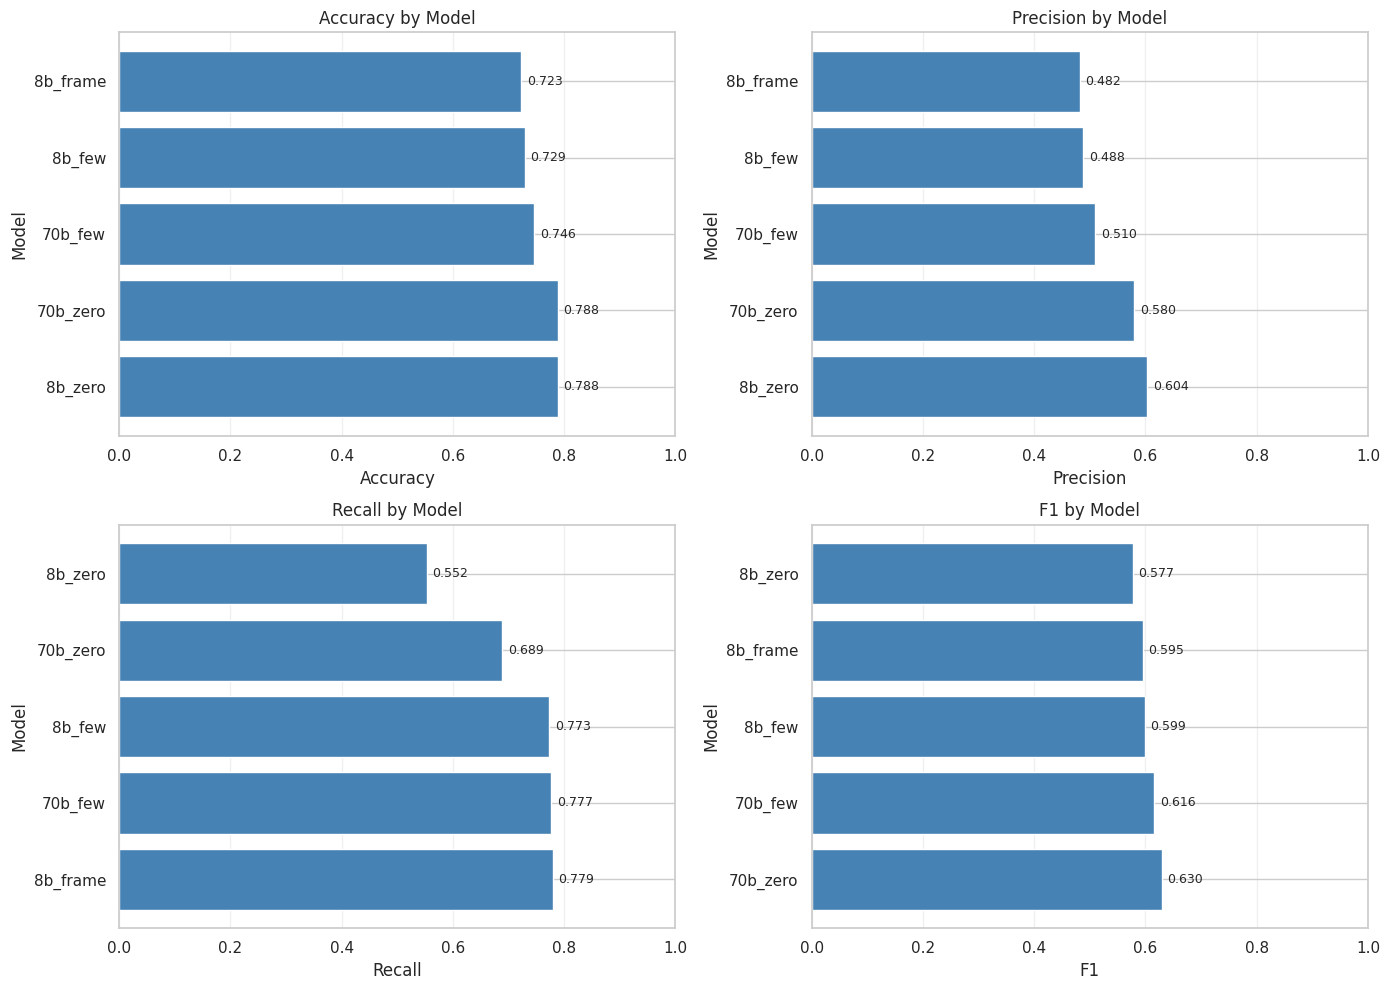

In [4]:
# Build evaluation dataframe with consistent text_ids
def build_eval_df(exp_name, df, task='is_conspiratorial'):
    """Build evaluation dataframe for a single experiment and task."""
    key = 'text_id'
    if key not in df.columns or key not in agg.columns:
        return None
    
    # Get prediction column
    pred_col = task
    if pred_col not in df.columns:
        return None
    
    # Get ground truth column (only conspiracy)
    if task == 'is_conspiratorial':
        gt_col = 'conspiracy_mv'
    else:
        return None
    
    if gt_col not in agg.columns:
        return None
    
    # Merge
    merged = df[[key, pred_col]].merge(
        agg[[key, gt_col]], on=key, how='inner'
    )
    
    # Fill NaN human labels as False (conservative)
    merged[gt_col] = merged[gt_col].fillna(False)
    
    # Coerce to boolean
    merged[pred_col] = merged[pred_col].map({True: True, False: False}).astype(bool)
    merged[gt_col] = merged[gt_col].map({True: True, False: False}).astype(bool)
    
    return merged

# Compute metrics for all experiments (conspiracy only)
results = []
for exp_name, df in experiments.items():
    eval_df = build_eval_df(exp_name, df, 'is_conspiratorial')
    if eval_df is None:
        continue
    
    pred_col = 'is_conspiratorial'
    gt_col = 'conspiracy_mv'
    
    y_true = eval_df[gt_col].to_numpy()
    y_pred = eval_df[pred_col].to_numpy()
    
    if len(y_true) == 0:
        continue
    
    # Compute metrics
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary', zero_division=0
    )
    
    results.append({
        'experiment': exp_name,
        'accuracy': acc,
        'precision': p,
        'recall': r,
        'f1': f1,
        'n': len(y_true)
    })

metrics_df = pd.DataFrame(results)

# Display summary table
if not metrics_df.empty:
    print("=" * 80)
    print("PERFORMANCE METRICS SUMMARY (CONSPIRACY CLASSIFICATION)")
    print("=" * 80)
    if 'missing_models' in globals() and missing_models:
        print(f"\n⚠ Note: {len(missing_models)} model(s) still running - results not included:")
        for _, name in missing_models:
            print(f"   - {name}")
        print()
    display(metrics_df.sort_values('f1', ascending=False))
    
    # Create visualization
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    for idx, metric in enumerate(['accuracy', 'precision', 'recall', 'f1']):
        ax = axes[idx // 2, idx % 2]
        metric_values = metrics_df.sort_values(metric, ascending=False)
        
        ax.barh(metric_values['experiment'], metric_values[metric], color='steelblue')
        ax.set_title(f'{metric.capitalize()} by Model')
        ax.set_xlabel(metric.capitalize())
        ax.set_ylabel('Model')
        ax.set_xlim(0, 1)
        ax.grid(axis='x', alpha=0.3)
        
        # Add value labels
        for i, v in enumerate(metric_values[metric]):
            ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.show()
else:
    print("No metrics computed.")


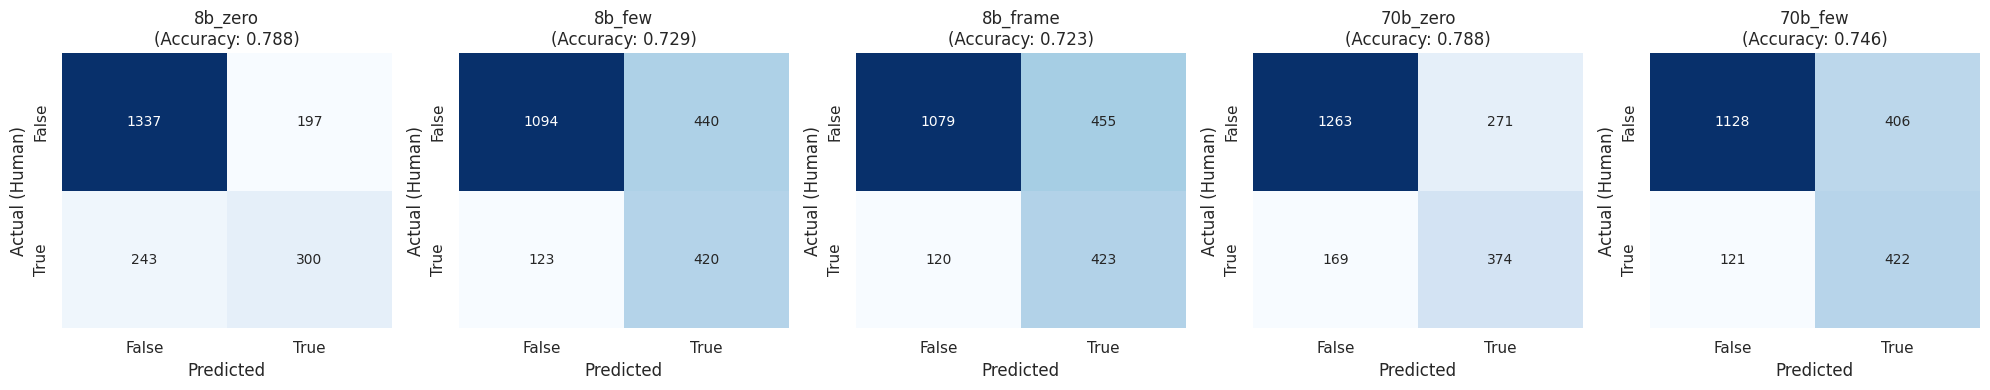

In [5]:
# Confusion Matrices for Conspiracy Classification
n_experiments = len(experiments)
fig, axes = plt.subplots(1, n_experiments, figsize=(4*n_experiments, 4))
if n_experiments == 1:
    axes = [axes]

for idx, (exp_name, df) in enumerate(experiments.items()):
    eval_df = build_eval_df(exp_name, df, 'is_conspiratorial')
    if eval_df is None:
        ax = axes[idx]
        ax.text(0.5, 0.5, f'No data\nfor {exp_name}', 
               ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f"{exp_name}")
        continue
    
    pred_col = 'is_conspiratorial'
    gt_col = 'conspiracy_mv'
    
    y_true = eval_df[gt_col].to_numpy()
    y_pred = eval_df[pred_col].to_numpy()
    
    cm = confusion_matrix(y_true, y_pred, labels=[False, True])
    acc = accuracy_score(y_true, y_pred)
    
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
               xticklabels=['False', 'True'], yticklabels=['False', 'True'])
    ax.set_title(f"{exp_name}\n(Accuracy: {acc:.3f})")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual (Human)')

plt.tight_layout()
plt.show()


## 3. Conspiracy Label Distribution

Compare how each model distributes conspiracy predictions vs human annotations.


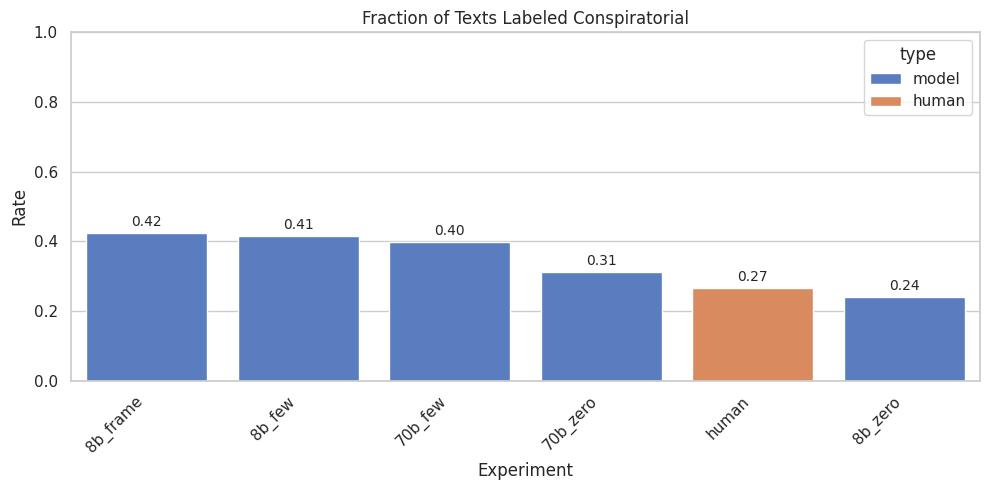

Conspiratorial Rate Summary:


,experiment,type,n,n_true,rate
2,8b_frame,model,2077,878,0.422725
1,8b_few,model,2077,860,0.414059
4,70b_few,model,2077,828,0.398652
3,70b_zero,model,2077,645,0.310544
5,human,human,2043,543,0.265786
0,8b_zero,model,2077,497,0.239287


In [6]:
# Conspiratorial rate comparison
rows = []
for name, df in experiments.items():
    if 'is_conspiratorial' not in df.columns:
        continue
    pred = df['is_conspiratorial'].astype(bool)
    n = len(pred)
    n_true = int((pred == True).sum())
    rows.append({
        'experiment': name,
        'type': 'model',
        'n': n,
        'n_true': n_true,
        'rate': n_true / n if n else np.nan
    })

# Add human
if 'agg' in globals() and agg is not None and 'conspiracy_mv' in agg.columns:
    h = agg['conspiracy_mv'].dropna().astype(bool)
    hn = len(h)
    hn_true = int((h == True).sum())
    rows.append({
        'experiment': 'human',
        'type': 'human',
        'n': hn,
        'n_true': hn_true,
        'rate': hn_true / hn if hn else np.nan
    })

rate_df = pd.DataFrame(rows).sort_values('rate', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=rate_df, x='experiment', y='rate', hue='type', dodge=False, ax=ax)
ax.set_ylim(0, 1)
ax.set_title('Fraction of Texts Labeled Conspiratorial')
ax.set_ylabel('Rate')
ax.set_xlabel('Experiment')
for container in ax.containers:
    ax.bar_label(container, labels=[f"{bar.get_height():.2f}" for bar in container], padding=3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Conspiratorial Rate Summary:")
display(rate_df)


## 4. Span Annotation Quality (Secondary Labels)

Compare span element identification rates across models and human annotators. These are the secondary labels extracted for texts classified as conspiratorial.

**Span Categories:**
- **Mandatory (Core)**: `plan` (plan_event), `secret` - at least one required when conspiratorial
- **Optional**: `out-group`, `in-group`, `call-to-action`


Span Presence Summary (Unique Text-Level):


,experiment,n_texts,rate_any,rate_out-group,rate_plan,rate_call-to-action,rate_in-group,rate_secret
0,8b_zero,2077,0.239287,0.165623,0.225806,0.059701,0.114588,0.195956
1,8b_few,2077,0.414059,0.303804,0.369283,0.056813,0.087626,0.363024
2,8b_frame,2077,0.421762,0.324988,0.393837,0.042850,0.089071,0.343284
3,70b_zero,2077,0.391430,0.267212,0.322099,0.265768,0.132403,0.092922
4,70b_few,2077,0.398652,0.306211,0.396726,0.195474,0.168994,0.162253
5,human,755,0.984106,0.585430,0.876821,0.256954,0.585430,0.331126


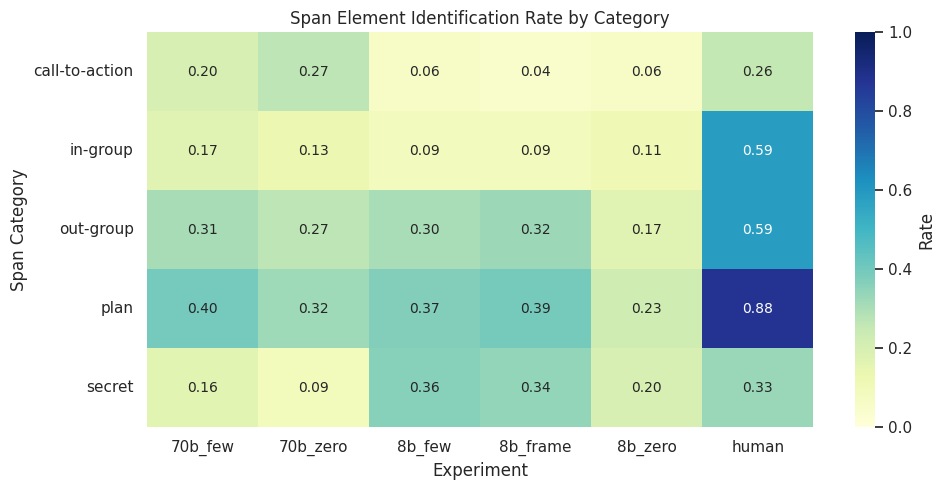

In [7]:
# Span element identification rates
SPAN_COLS = ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']

def is_present(col: pd.Series) -> pd.Series:
    """Robust check for span presence."""
    s = col.astype(str).str.strip()
    sl = s.str.lower()
    return (
        col.notna() &
        s.ne('') &
        sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]')
    )

# Build span files for models
span_files = {}
for name, class_path in model_files.items():
    span_path = Path(str(class_path).replace('_all_classifications.csv', '_all_span_annotations.csv'))
    span_files[name] = span_path

span_presence_rows = []

# Models: unique text-level presence
for name, spath in span_files.items():
    if not spath.exists():
        continue
    df = pd.read_csv(spath)
    cols = [c for c in SPAN_COLS if c in df.columns]
    if not cols or 'text_id' not in df.columns:
        continue
    
    pres = df[cols].apply(is_present)
    pres['text_id'] = df['text_id']
    uniq = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
    
    cat_rates = uniq[cols].mean().to_dict()
    any_present = uniq[cols].any(axis=1)
    
    span_presence_rows.append({
        'experiment': name,
        'n_texts': len(uniq),
        'rate_any': float(any_present.mean()),
        **{f'rate_{c}': float(cat_rates.get(c, np.nan)) for c in cols}
    })

# Human: unique text-level presence
if 'human_spans' in globals() and human_spans is not None and 'text_id' in human_spans.columns:
    hs = human_spans.copy()
    cols = [c for c in SPAN_COLS if c in hs.columns]
    if cols:
        pres = hs[cols].apply(is_present)
        pres['text_id'] = hs['text_id']
        human_unique = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
        
        cat_rates = human_unique[cols].mean().to_dict()
        any_present = human_unique[cols].any(axis=1)
        
        span_presence_rows.append({
            'experiment': 'human',
            'n_texts': len(human_unique),
            'rate_any': float(any_present.mean()),
            **{f'rate_{c}': float(cat_rates.get(c, np.nan)) for c in cols}
        })

span_presence = pd.DataFrame(span_presence_rows)

print("Span Presence Summary (Unique Text-Level):")
display(span_presence)

# Heatmap
if not span_presence.empty:
    long_rows = []
    for _, r in span_presence.iterrows():
        for c in SPAN_COLS:
            key = f'rate_{c}'
            if key in r and not pd.isna(r[key]):
                long_rows.append({
                    'experiment': r['experiment'],
                    'category': c,
                    'rate': r[key]
                })
    
    if long_rows:
        long_df = pd.DataFrame(long_rows)
        pivot = long_df.pivot_table(index='category', columns='experiment', values='rate')
        
        plt.figure(figsize=(10, 5))
        sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, cbar_kws={'label': 'Rate'})
        plt.title('Span Element Identification Rate by Category')
        plt.xlabel('Experiment')
        plt.ylabel('Span Category')
        plt.tight_layout()
        plt.show()
    else:
        print('No per-category data to plot.')
else:
    print('No span presence data available.')


## 4b. Span Label Agreement Analysis

Compute agreement metrics for span labels between models and human annotators, considering mandatory vs optional categories.


## 4c. Span Text Agreement Analysis (Text Substring Matching)

This section analyzes agreement based on the actual text substrings identified as spans, not just presence/absence. We compare whether models and humans identified the same or similar text segments.

**Metrics:**
- **Exact Match Rate**: Percentage of spans that match exactly (after normalization)
- **Character-level F1**: Precision, Recall, F1 based on character overlap
- **Overlap Rate**: Percentage of spans with any character overlap
- **Average Overlap Ratio**: Mean overlap (intersection/union) for overlapping spans


In [9]:
# Helper Functions for Span Text Comparison
import re
from collections import defaultdict

def normalize_span_text(text):
    """Normalize span text for comparison."""
    if pd.isna(text) or text == '':
        return ''
    # Convert to string, lowercase, strip whitespace
    text = str(text).strip().lower()
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text)
    return text

def compute_character_overlap(text1, text2):
    """Compute character-level overlap metrics between two texts."""
    text1 = normalize_span_text(text1)
    text2 = normalize_span_text(text2)
    
    if not text1 or not text2:
        return {'intersection': 0, 'union': len(text1) + len(text2), 'text1_len': len(text1), 'text2_len': len(text2)}
    
    # Character sets (multiset - count characters)
    from collections import Counter
    chars1 = Counter(text1)
    chars2 = Counter(text2)
    
    intersection = sum((chars1 & chars2).values())
    union = sum((chars1 | chars2).values())
    
    return {
        'intersection': intersection,
        'union': union,
        'text1_len': len(text1),
        'text2_len': len(text2),
        'jaccard': intersection / union if union > 0 else 0.0,
        'exact_match': text1 == text2
    }

def compute_span_metrics(human_spans, model_spans):
    """
    Compute agreement metrics between human and model spans for a single category.
    
    Args:
        human_spans: list of normalized span texts from human
        model_spans: list of normalized span texts from model
    
    Returns:
        dict with metrics
    """
    human_spans = [normalize_span_text(s) for s in human_spans if normalize_span_text(s)]
    model_spans = [normalize_span_text(s) for s in model_spans if normalize_span_text(s)]
    
    if not human_spans and not model_spans:
        return {
            'exact_match_rate': 1.0,
            'overlap_rate': 1.0,
            'precision': 1.0,
            'recall': 1.0,
            'f1': 1.0,
            'avg_overlap_ratio': 1.0,
            'n_human': 0,
            'n_model': 0
        }
    
    if not human_spans:
        return {
            'exact_match_rate': 0.0,
            'overlap_rate': 0.0,
            'precision': 0.0,
            'recall': 1.0,  # No human spans = perfect recall
            'f1': 0.0,
            'avg_overlap_ratio': 0.0,
            'n_human': 0,
            'n_model': len(model_spans)
        }
    
    if not model_spans:
        return {
            'exact_match_rate': 0.0,
            'overlap_rate': 0.0,
            'precision': 1.0,  # No model spans = perfect precision
            'recall': 0.0,
            'f1': 0.0,
            'avg_overlap_ratio': 0.0,
            'n_human': len(human_spans),
            'n_model': 0
        }
    
    # Find best matches (greedy matching)
    # For each model span, find best matching human span
    matched_human = set()
    exact_matches = 0
    overlaps = []
    overlap_ratios = []
    
    for model_span in model_spans:
        best_match_idx = None
        best_overlap = 0
        best_exact = False
        
        for idx, human_span in enumerate(human_spans):
            if idx in matched_human:
                continue
            
            overlap_info = compute_character_overlap(model_span, human_span)
            overlap_score = overlap_info['jaccard']
            
            if overlap_info['exact_match']:
                best_match_idx = idx
                best_overlap = 1.0
                best_exact = True
                break
            elif overlap_score > best_overlap:
                best_overlap = overlap_score
                best_match_idx = idx
        
        if best_match_idx is not None:
            matched_human.add(best_match_idx)
            if best_exact:
                exact_matches += 1
            if best_overlap > 0:
                overlaps.append(1)
                overlap_ratios.append(best_overlap)
            else:
                overlaps.append(0)
        else:
            overlaps.append(0)
    
    # Also check unmatched human spans (for recall)
    unmatched_human = len(human_spans) - len(matched_human)
    
    # Compute metrics
    n_human = len(human_spans)
    n_model = len(model_spans)
    n_matched = len(matched_human)
    
    exact_match_rate = exact_matches / n_model if n_model > 0 else 0.0
    overlap_rate = sum(overlaps) / n_model if n_model > 0 else 0.0
    avg_overlap_ratio = np.mean(overlap_ratios) if overlap_ratios else 0.0
    
    # Precision: of model spans, how many matched?
    precision = n_matched / n_model if n_model > 0 else 0.0
    
    # Recall: of human spans, how many were matched?
    recall = n_matched / n_human if n_human > 0 else 0.0
    
    # F1
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return {
        'exact_match_rate': exact_match_rate,
        'overlap_rate': overlap_rate,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'avg_overlap_ratio': avg_overlap_ratio,
        'n_human': n_human,
        'n_model': n_model,
        'n_matched': n_matched
    }

print("✓ Helper functions defined for span text comparison")


✓ Helper functions defined for span text comparison


### Individual Model vs Human Analysis

Detailed span text agreement metrics for each model compared to human annotations.


In [35]:
# Individual Model vs Human Span Text Agreement
SPAN_COLS = ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']
MANDATORY_SPANS = ['plan', 'secret']
OPTIONAL_SPANS = ['out-group', 'in-group', 'call-to-action']

# Load human spans (raw, not aggregated)
human_spans_raw = None
if 'human_spans' in globals() and human_spans is not None:
    human_spans_raw = human_spans.copy()

# Load model spans
span_files = {}
for name, class_path in model_files.items():
    span_path = Path(str(class_path).replace('_all_classifications.csv', '_all_span_annotations.csv'))
    span_files[name] = span_path

individual_results = []

for model_name, span_path in span_files.items():
    if not span_path.exists():
        continue
    
    if human_spans_raw is None:
        continue
    
    model_spans_df = pd.read_csv(span_path)
    
    # Process each text_id
    all_text_ids = set(model_spans_df['text_id'].unique()) & set(human_spans_raw['text_id'].unique())
    
    print(f"\n{'='*80}")
    print(f"Analyzing: {model_name}")
    print(f"Common text_ids: {len(all_text_ids):,}")
    print(f"{'='*80}")
    
    model_results = []
    
    for text_id in all_text_ids:
        # Get human spans for this text
        human_text_spans = human_spans_raw[human_spans_raw['text_id'] == text_id]
        # Get model spans for this text
        model_text_spans = model_spans_df[model_spans_df['text_id'] == text_id]
        
        # Compute metrics per category
        for category in SPAN_COLS:
            if category not in human_text_spans.columns or category not in model_text_spans.columns:
                continue
            
            # Extract span texts
            human_spans_list = human_text_spans[category].dropna().tolist()
            model_spans_list = model_text_spans[category].dropna().tolist()
            
            # Filter out empty strings
            human_spans_list = [s for s in human_spans_list if normalize_span_text(s)]
            model_spans_list = [s for s in model_spans_list if normalize_span_text(s)]
            
            # Compute metrics
            metrics = compute_span_metrics(human_spans_list, model_spans_list)
            
            model_results.append({
                'text_id': text_id,
                'category': category,
                **metrics
            })
    
    # Aggregate per category
    if model_results:
        model_results_df = pd.DataFrame(model_results)
        
        print(f"\nPer-Category Summary:")
        category_summary = []
        
        for category in SPAN_COLS:
            cat_data = model_results_df[model_results_df['category'] == category]
            if len(cat_data) == 0:
                continue
            
            # Aggregate metrics (weighted by number of spans)
            total_human = cat_data['n_human'].sum()
            total_model = cat_data['n_model'].sum()
            total_matched = cat_data['n_matched'].sum()
            
            # Average metrics
            avg_exact = cat_data['exact_match_rate'].mean()
            avg_overlap_rate = cat_data['overlap_rate'].mean()
            avg_precision = cat_data['precision'].mean()
            avg_recall = cat_data['recall'].mean()
            avg_f1 = cat_data['f1'].mean()
            avg_overlap_ratio = cat_data[cat_data['avg_overlap_ratio'] > 0]['avg_overlap_ratio'].mean()
            if pd.isna(avg_overlap_ratio):
                avg_overlap_ratio = 0.0
            
            # Overall precision/recall (micro-averaged)
            overall_precision = total_matched / total_model if total_model > 0 else 0.0
            overall_recall = total_matched / total_human if total_human > 0 else 0.0
            overall_f1 = 2 * overall_precision * overall_recall / (overall_precision + overall_recall) if (overall_precision + overall_recall) > 0 else 0.0
            
            category_summary.append({
                'experiment': model_name,
                'category': category,
                'exact_match_rate': avg_exact,
                'overlap_rate': avg_overlap_rate,
                'precision': overall_precision,
                'recall': overall_recall,
                'f1': overall_f1,
                'avg_overlap_ratio': avg_overlap_ratio,
                'n_texts': len(cat_data),
                'total_human_spans': total_human,
                'total_model_spans': total_model,
                'total_matched': total_matched
            })
            
            print(f"  {category:15s}: F1={overall_f1:.3f}, P={overall_precision:.3f}, R={overall_recall:.3f}, "
                  f"Exact={avg_exact:.3f}, Overlap={avg_overlap_rate:.3f}")
        
        individual_results.extend(category_summary)

if individual_results:
    individual_df = pd.DataFrame(individual_results)
    print(f"\n{'='*80}")
    print("INDIVIDUAL MODEL RESULTS SUMMARY")
    print(f"{'='*80}")
    display(individual_df)
else:
    print("⚠ No results computed. Check data availability.")



Analyzing: 8b_zero
Common text_ids: 749

Per-Category Summary:
  out-group      : F1=0.481, P=0.780, R=0.347, Exact=0.413, Overlap=0.591
  plan           : F1=0.499, P=0.894, R=0.346, Exact=0.109, Overlap=0.441
  call-to-action : F1=0.289, P=0.512, R=0.202, Exact=0.701, Overlap=0.748
  in-group       : F1=0.376, P=0.727, R=0.254, Exact=0.399, Overlap=0.529
  secret         : F1=0.407, P=0.429, R=0.388, Exact=0.485, Overlap=0.622

Analyzing: 8b_few
Common text_ids: 749

Per-Category Summary:
  out-group      : F1=0.621, P=0.724, R=0.543, Exact=0.375, Overlap=0.653
  plan           : F1=0.635, P=0.883, R=0.496, Exact=0.096, Overlap=0.571
  call-to-action : F1=0.278, P=0.571, R=0.183, Exact=0.718, Overlap=0.758
  in-group       : F1=0.318, P=0.745, R=0.202, Exact=0.415, Overlap=0.507
  secret         : F1=0.452, P=0.375, R=0.569, Exact=0.326, Overlap=0.527

Analyzing: 8b_frame
Common text_ids: 749

Per-Category Summary:
  out-group      : F1=0.624, P=0.709, R=0.557, Exact=0.362, Overlap=

,experiment,category,exact_match_rate,overlap_rate,precision,recall,f1,avg_overlap_ratio,n_texts,total_human_spans,total_model_spans,total_matched
0,8b_zero,out-group,0.412550,0.591455,0.780172,0.347409,0.480744,0.794794,749,521,232,181.0
1,8b_zero,plan,0.109479,0.440587,0.893688,0.345758,0.498610,0.527978,749,778,301,269.0
2,8b_zero,call-to-action,0.700935,0.747664,0.511628,0.201835,0.289474,0.958178,749,218,86,44.0
3,8b_zero,in-group,0.399199,0.528705,0.727273,0.253968,0.376471,0.827653,749,504,176,128.0
4,8b_zero,secret,0.484646,0.622163,0.429134,0.387900,0.407477,0.840584,749,281,254,109.0
5,8b_few,out-group,0.375167,0.652870,0.723785,0.543186,0.620614,0.720477,749,521,391,283.0
6,8b_few,plan,0.096128,0.571429,0.883295,0.496144,0.635391,0.501740,749,778,437,386.0
7,8b_few,call-to-action,0.718291,0.758344,0.571429,0.183486,0.277778,0.973776,749,218,70,40.0
8,8b_few,in-group,0.415220,0.507343,0.744526,0.202381,0.318253,0.875000,749,504,137,102.0
9,8b_few,secret,0.325768,0.527370,0.374707,0.569395,0.451977,0.764224,749,281,427,160.0


### Comparative Analysis: All Models vs Human

Compare all models' span text agreement performance against human annotations.


COMPARATIVE ANALYSIS: ALL MODELS VS HUMAN

1. Overall Performance by Model:


,f1,precision,recall,exact_match_rate,overlap_rate,avg_overlap_ratio
experiment,,,,,,
70b_zero,0.511625,0.680067,0.441827,0.421362,0.635514,0.795920
8b_few,0.460803,0.659548,0.398918,0.386115,0.603471,0.767044
8b_frame,0.459997,0.682611,0.395786,0.391722,0.610681,0.765542
8b_zero,0.410555,0.668379,0.307374,0.421362,0.586115,0.789837



2. Performance by Category (across all models):


,f1,precision,recall,exact_match_rate,overlap_rate,avg_overlap_ratio
category,,,,,,
plan,0.604170,0.887605,0.461761,0.101135,0.542724,0.518214
out-group,0.588619,0.741251,0.497121,0.393191,0.640187,0.749445
secret,0.413786,0.435413,0.438612,0.438585,0.592790,0.823045
in-group,0.366890,0.748977,0.244544,0.419559,0.528705,0.859153
call-to-action,0.330258,0.550011,0.287844,0.673231,0.740320,0.948073



3. Mandatory vs Optional Spans:


,f1,precision,recall,exact_match_rate,overlap_rate
span_type,,,,,
Mandatory,0.508978,0.661509,0.450187,0.269860,0.567757
Optional,0.428589,0.680080,0.343170,0.495327,0.636404


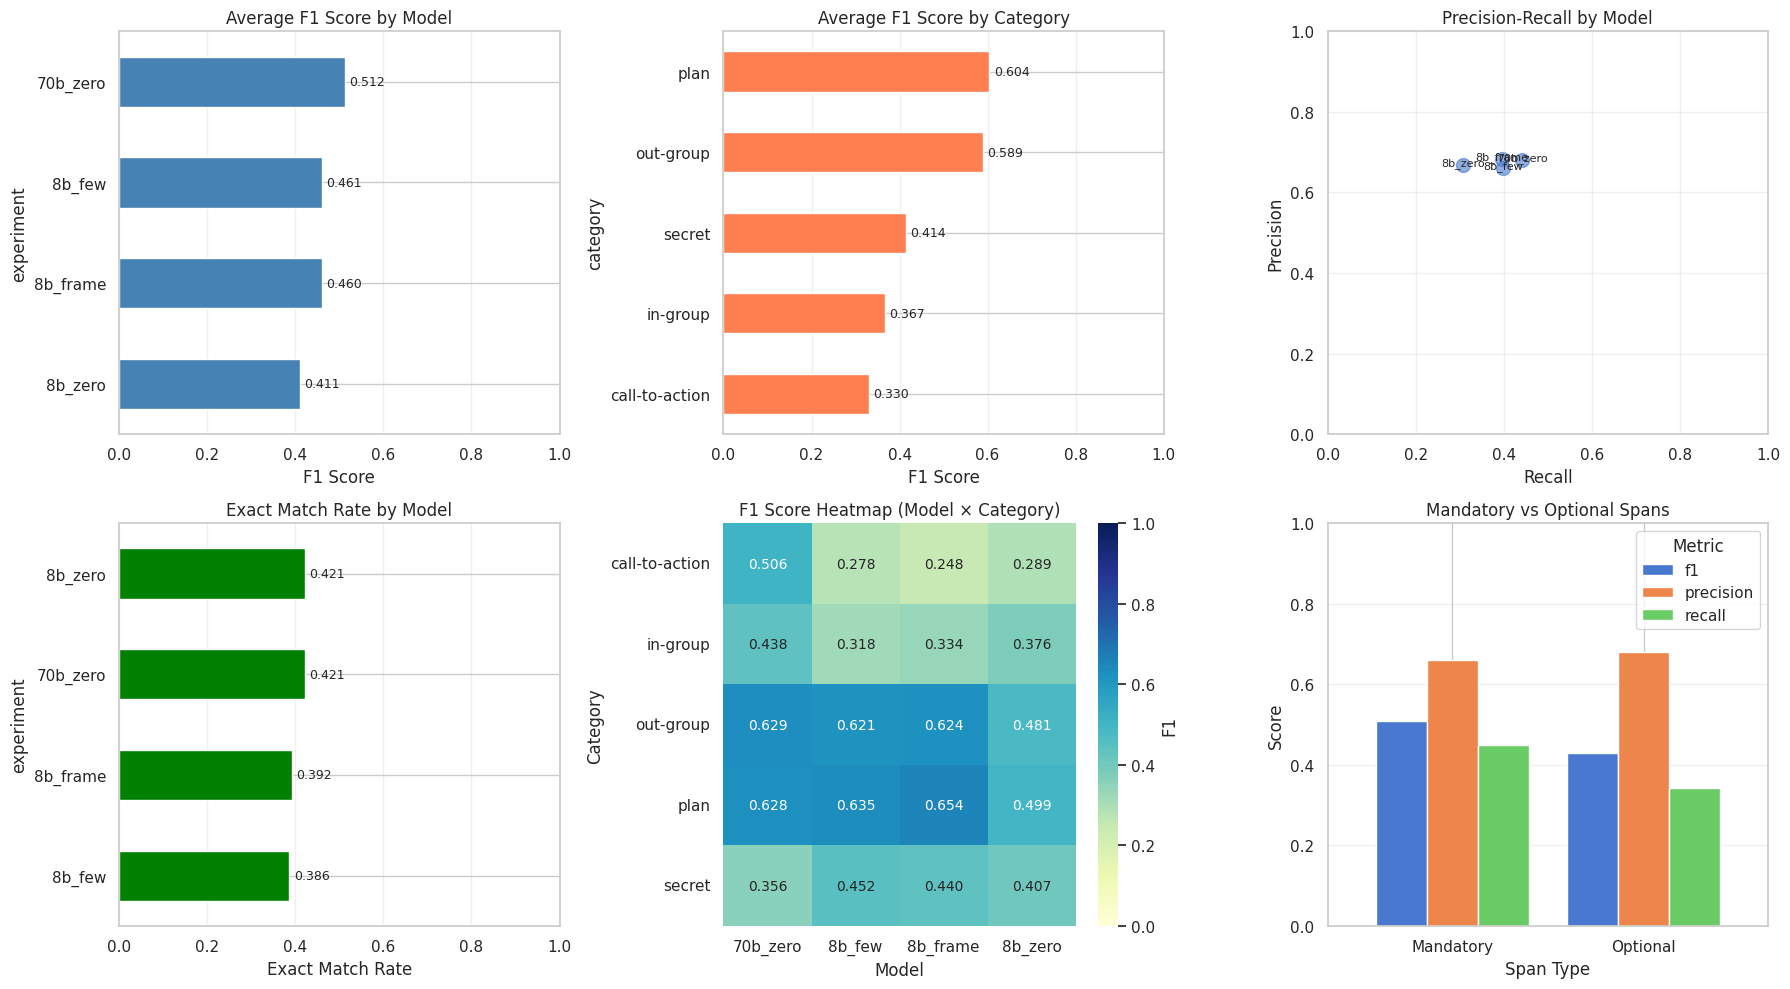


BEST/WORST PERFORMING MODELS

🏆 Best F1 Score: 70b_zero (F1=0.5116)
⚠ Worst F1 Score: 8b_zero (F1=0.4106)
🎯 Best Exact Match: 70b_zero (Rate=0.4214)

📊 Best Performing Categories:
   out-group      : 70b_zero (F1=0.6295)
   plan           : 8b_frame (F1=0.6543)
   call-to-action : 70b_zero (F1=0.5057)
   in-group       : 70b_zero (F1=0.4385)
   secret         : 8b_few (F1=0.4520)


In [36]:
# Comparative Analysis: All Models vs Human
if 'individual_df' in globals() and not individual_df.empty:
    print("=" * 80)
    print("COMPARATIVE ANALYSIS: ALL MODELS VS HUMAN")
    print("=" * 80)
    
    # Summary table by model
    print("\n1. Overall Performance by Model:")
    model_summary = individual_df.groupby('experiment').agg({
        'f1': 'mean',
        'precision': 'mean',
        'recall': 'mean',
        'exact_match_rate': 'mean',
        'overlap_rate': 'mean',
        'avg_overlap_ratio': 'mean'
    }).sort_values('f1', ascending=False)
    display(model_summary)
    
    # Summary by category
    print("\n2. Performance by Category (across all models):")
    category_summary = individual_df.groupby('category').agg({
        'f1': 'mean',
        'precision': 'mean',
        'recall': 'mean',
        'exact_match_rate': 'mean',
        'overlap_rate': 'mean',
        'avg_overlap_ratio': 'mean'
    }).sort_values('f1', ascending=False)
    display(category_summary)
    
    # Mandatory vs Optional
    print("\n3. Mandatory vs Optional Spans:")
    individual_df['span_type'] = individual_df['category'].apply(
        lambda x: 'Mandatory' if x in MANDATORY_SPANS else 'Optional'
    )
    type_summary = individual_df.groupby('span_type').agg({
        'f1': 'mean',
        'precision': 'mean',
        'recall': 'mean',
        'exact_match_rate': 'mean',
        'overlap_rate': 'mean'
    })
    display(type_summary)
    
    # Visualizations
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # 1. F1 by Model
    ax = axes[0, 0]
    f1_by_model = individual_df.groupby('experiment')['f1'].mean().sort_values(ascending=True)
    f1_by_model.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title('Average F1 Score by Model')
    ax.set_xlabel('F1 Score')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(f1_by_model):
        ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
    
    # 2. F1 by Category
    ax = axes[0, 1]
    f1_by_cat = individual_df.groupby('category')['f1'].mean().sort_values(ascending=True)
    f1_by_cat.plot(kind='barh', ax=ax, color='coral')
    ax.set_title('Average F1 Score by Category')
    ax.set_xlabel('F1 Score')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(f1_by_cat):
        ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
    
    # 3. Precision-Recall by Model
    ax = axes[0, 2]
    pr_by_model = individual_df.groupby('experiment').agg({'precision': 'mean', 'recall': 'mean'})
    ax.scatter(pr_by_model['recall'], pr_by_model['precision'], s=100, alpha=0.6)
    for model in pr_by_model.index:
        ax.annotate(model, (pr_by_model.loc[model, 'recall'], pr_by_model.loc[model, 'precision']),
                   fontsize=8, ha='center')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title('Precision-Recall by Model')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    
    # 4. Exact Match Rate by Model
    ax = axes[1, 0]
    exact_by_model = individual_df.groupby('experiment')['exact_match_rate'].mean().sort_values(ascending=True)
    exact_by_model.plot(kind='barh', ax=ax, color='green')
    ax.set_title('Exact Match Rate by Model')
    ax.set_xlabel('Exact Match Rate')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(exact_by_model):
        ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
    
    # 5. Heatmap: F1 by Model and Category
    ax = axes[1, 1]
    pivot_f1 = individual_df.pivot_table(index='category', columns='experiment', values='f1')
    sns.heatmap(pivot_f1, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'F1'})
    ax.set_title('F1 Score Heatmap (Model × Category)')
    ax.set_xlabel('Model')
    ax.set_ylabel('Category')
    
    # 6. Mandatory vs Optional Comparison
    ax = axes[1, 2]
    type_metrics = individual_df.groupby('span_type').agg({
        'f1': 'mean',
        'precision': 'mean',
        'recall': 'mean'
    })
    type_metrics.plot(kind='bar', ax=ax, width=0.8)
    ax.set_title('Mandatory vs Optional Spans')
    ax.set_ylabel('Score')
    ax.set_xlabel('Span Type')
    ax.legend(title='Metric', loc='best')
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(0, 1)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0)
    
    plt.tight_layout()
    plt.show()
    
    # Best/Worst performing models
    print("\n" + "=" * 80)
    print("BEST/WORST PERFORMING MODELS")
    print("=" * 80)
    best_f1 = individual_df.groupby('experiment')['f1'].mean().idxmax()
    worst_f1 = individual_df.groupby('experiment')['f1'].mean().idxmin()
    best_exact = individual_df.groupby('experiment')['exact_match_rate'].mean().idxmax()
    
    print(f"\n🏆 Best F1 Score: {best_f1} (F1={individual_df.groupby('experiment')['f1'].mean().max():.4f})")
    print(f"⚠ Worst F1 Score: {worst_f1} (F1={individual_df.groupby('experiment')['f1'].mean().min():.4f})")
    print(f"🎯 Best Exact Match: {best_exact} (Rate={individual_df.groupby('experiment')['exact_match_rate'].mean().max():.4f})")
    
    # Best category performance
    print(f"\n📊 Best Performing Categories:")
    for cat in SPAN_COLS:
        cat_data = individual_df[individual_df['category'] == cat]
        if len(cat_data) > 0:
            best_cat_model = cat_data.groupby('experiment')['f1'].mean().idxmax()
            best_cat_f1 = cat_data.groupby('experiment')['f1'].mean().max()
            print(f"   {cat:15s}: {best_cat_model} (F1={best_cat_f1:.4f})")
    
else:
    print("⚠ Individual results not available. Run previous cell first.")


Computing agreement over 749 common text_ids

SPAN LABEL AGREEMENT METRICS (Models vs Human)


,experiment,any_span_agreement,mandatory_agreement,optional_agreement,avg_jaccard,out-group_agreement,plan_agreement,call-to-action_agreement,in-group_agreement,secret_agreement
3,70b_zero,0.631509,0.574099,0.696929,0.370939,0.675567,0.566088,0.687583,0.571429,0.690254
2,8b_frame,0.642190,0.631509,0.638184,0.353160,0.650200,0.592790,0.769025,0.518024,0.530040
1,8b_few,0.632844,0.627503,0.623498,0.343614,0.658211,0.571429,0.758344,0.511348,0.530040
0,8b_zero,0.431242,0.436582,0.493992,0.262216,0.595461,0.440587,0.747664,0.536716,0.623498


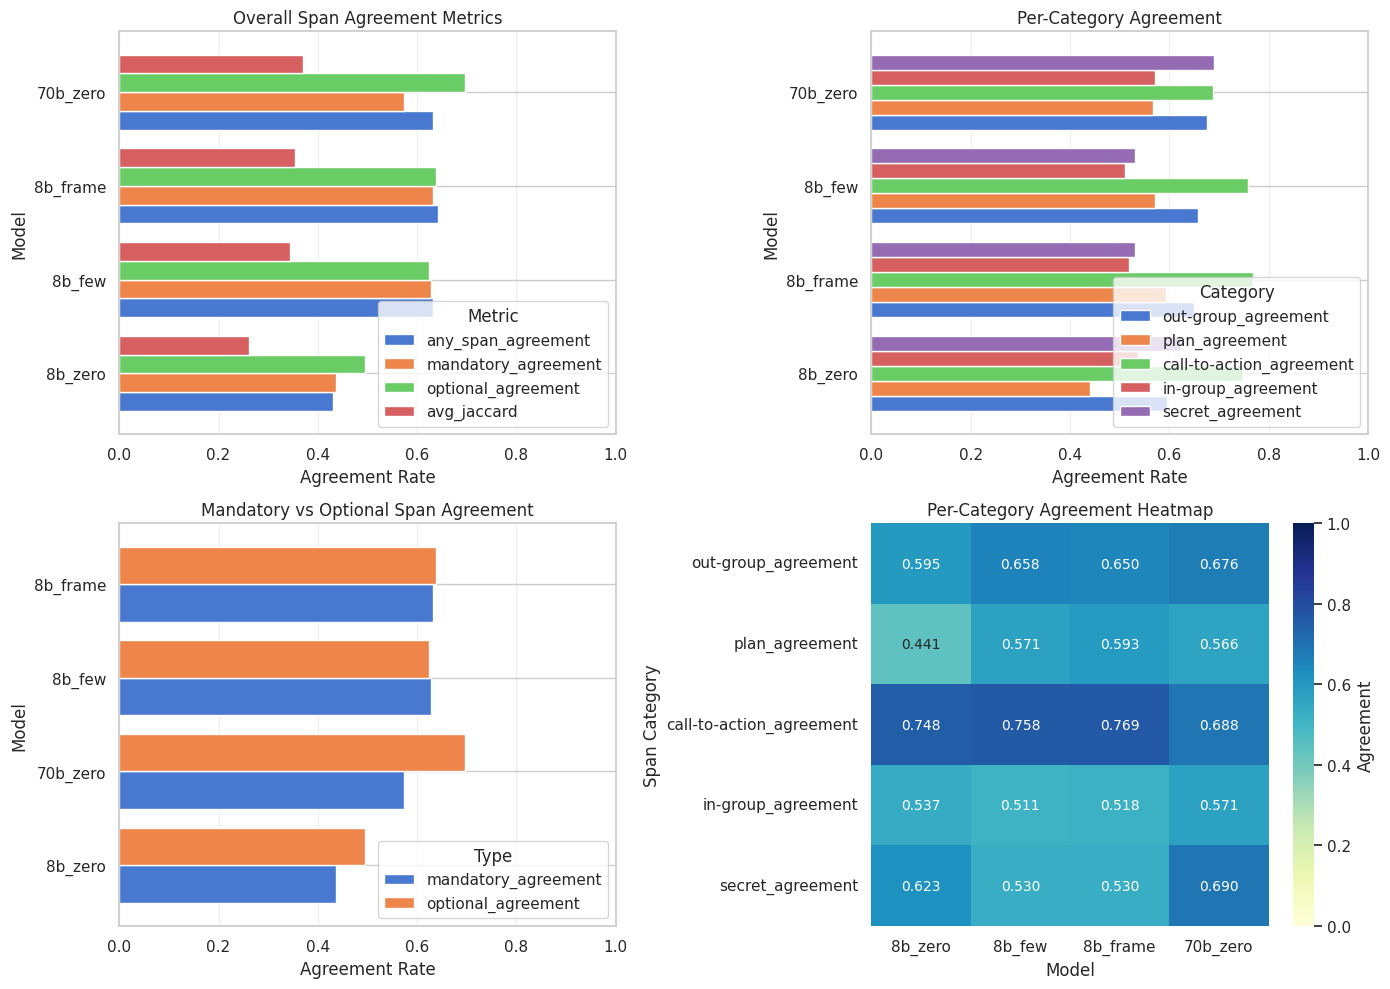


AGREEMENT SUMMARY STATISTICS
Mandatory Spans (plan, secret):
  - Mean agreement: 0.5674
  - Range: 0.4366 - 0.6315

Optional Spans (out-group, in-group, call-to-action):
  - Mean agreement: 0.6132
  - Range: 0.4940 - 0.6969

Jaccard Similarity (span set overlap):
  - Mean: 0.3325
  - Range: 0.2622 - 0.3709


In [37]:
# Span Label Agreement Analysis
# Compare agreement between models and human for span annotations

SPAN_COLS = ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']
MANDATORY_SPANS = ['plan', 'secret']  # Core spans required when conspiratorial
OPTIONAL_SPANS = ['out-group', 'in-group', 'call-to-action']

def is_present(col: pd.Series) -> pd.Series:
    """Robust check for span presence."""
    s = col.astype(str).str.strip()
    sl = s.str.lower()
    return (
        col.notna() &
        s.ne('') &
        sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]')
    )

# Build human span presence (unique text-level)
human_span_presence = None
if 'human_spans' in globals() and human_spans is not None and 'text_id' in human_spans.columns:
    hs = human_spans.copy()
    cols = [c for c in SPAN_COLS if c in hs.columns]
    if cols:
        pres = hs[cols].apply(is_present)
        pres['text_id'] = hs['text_id']
        human_span_presence = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
        # Add mandatory and optional flags
        human_span_presence['any_mandatory'] = human_span_presence[[c for c in MANDATORY_SPANS if c in human_span_presence.columns]].any(axis=1)
        human_span_presence['any_optional'] = human_span_presence[[c for c in OPTIONAL_SPANS if c in human_span_presence.columns]].any(axis=1)
        human_span_presence['any_span'] = human_span_presence[cols].any(axis=1)

# Build model span presence
span_files = {}
for name, class_path in model_files.items():
    span_path = Path(str(class_path).replace('_all_classifications.csv', '_all_span_annotations.csv'))
    span_files[name] = span_path

model_span_presence = {}
for name, spath in span_files.items():
    if not spath.exists():
        continue
    df = pd.read_csv(spath)
    cols = [c for c in SPAN_COLS if c in df.columns]
    if not cols or 'text_id' not in df.columns:
        continue
    
    pres = df[cols].apply(is_present)
    pres['text_id'] = df['text_id']
    uniq = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
    # Add mandatory and optional flags
    uniq['any_mandatory'] = uniq[[c for c in MANDATORY_SPANS if c in uniq.columns]].any(axis=1)
    uniq['any_optional'] = uniq[[c for c in OPTIONAL_SPANS if c in uniq.columns]].any(axis=1)
    uniq['any_span'] = uniq[cols].any(axis=1)
    model_span_presence[name] = uniq

# Compute agreement metrics
if human_span_presence is not None and len(model_span_presence) > 0:
    agreement_results = []
    
    # Get common text_ids
    common_text_ids = set(human_span_presence['text_id'].unique())
    for name in model_span_presence:
        common_text_ids = common_text_ids.intersection(set(model_span_presence[name]['text_id'].unique()))
    
    print(f"Computing agreement over {len(common_text_ids):,} common text_ids\n")
    
    # Merge human with each model
    for name, model_spans in model_span_presence.items():
        merged = human_span_presence.merge(
            model_spans,
            on='text_id',
            how='inner',
            suffixes=('_human', '_model')
        )
        
        # Overall agreement (any span presence)
        any_span_agreement = (merged['any_span_human'] == merged['any_span_model']).mean()
        
        # Mandatory spans agreement
        mandatory_agreement = (merged['any_mandatory_human'] == merged['any_mandatory_model']).mean()
        
        # Optional spans agreement
        optional_agreement = (merged['any_optional_human'] == merged['any_optional_model']).mean()
        
        # Per-category agreement
        category_agreements = {}
        for cat in SPAN_COLS:
            human_col = f'{cat}_human'
            model_col = f'{cat}_model'
            if human_col in merged.columns and model_col in merged.columns:
                category_agreements[cat] = (merged[human_col] == merged[model_col]).mean()
        
        # Jaccard similarity for span sets (presence-based)
        # For each text, compute Jaccard similarity of present categories
        jaccard_scores = []
        for _, row in merged.iterrows():
            human_set = set([cat for cat in SPAN_COLS if row.get(f'{cat}_human', False)])
            model_set = set([cat for cat in SPAN_COLS if row.get(f'{cat}_model', False)])
            if len(human_set) == 0 and len(model_set) == 0:
                jaccard_scores.append(1.0)  # Both empty = perfect agreement
            elif len(human_set) == 0 or len(model_set) == 0:
                jaccard_scores.append(0.0)  # One empty, one not = no agreement
            else:
                intersection = len(human_set & model_set)
                union = len(human_set | model_set)
                jaccard_scores.append(intersection / union if union > 0 else 0.0)
        
        avg_jaccard = np.mean(jaccard_scores) if jaccard_scores else 0.0
        
        agreement_results.append({
            'experiment': name,
            'any_span_agreement': any_span_agreement,
            'mandatory_agreement': mandatory_agreement,
            'optional_agreement': optional_agreement,
            'avg_jaccard': avg_jaccard,
            **{f'{cat}_agreement': category_agreements.get(cat, np.nan) for cat in SPAN_COLS}
        })
    
    agreement_df = pd.DataFrame(agreement_results)
    
    print("=" * 80)
    print("SPAN LABEL AGREEMENT METRICS (Models vs Human)")
    print("=" * 80)
    display(agreement_df.sort_values('avg_jaccard', ascending=False))
    
    # Visualization
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. Overall agreement metrics
    ax = axes[0, 0]
    metrics_to_plot = ['any_span_agreement', 'mandatory_agreement', 'optional_agreement', 'avg_jaccard']
    plot_data = agreement_df.set_index('experiment')[metrics_to_plot].sort_values('avg_jaccard', ascending=True)
    plot_data.plot(kind='barh', ax=ax, width=0.8)
    ax.set_title('Overall Span Agreement Metrics')
    ax.set_xlabel('Agreement Rate')
    ax.set_ylabel('Model')
    ax.legend(title='Metric', loc='best')
    ax.grid(axis='x', alpha=0.3)
    ax.set_xlim(0, 1)
    
    # 2. Per-category agreement
    ax = axes[0, 1]
    category_cols = [f'{cat}_agreement' for cat in SPAN_COLS if f'{cat}_agreement' in agreement_df.columns]
    if category_cols:
        cat_data = agreement_df.set_index('experiment')[category_cols].sort_values(category_cols[0], ascending=True)
        cat_data.plot(kind='barh', ax=ax, width=0.8)
        ax.set_title('Per-Category Agreement')
        ax.set_xlabel('Agreement Rate')
        ax.set_ylabel('Model')
        ax.legend(title='Category', loc='best')
        ax.grid(axis='x', alpha=0.3)
        ax.set_xlim(0, 1)
    
    # 3. Mandatory vs Optional comparison
    ax = axes[1, 0]
    mand_opt_data = agreement_df.set_index('experiment')[['mandatory_agreement', 'optional_agreement']].sort_values('mandatory_agreement', ascending=True)
    mand_opt_data.plot(kind='barh', ax=ax, width=0.8)
    ax.set_title('Mandatory vs Optional Span Agreement')
    ax.set_xlabel('Agreement Rate')
    ax.set_ylabel('Model')
    ax.legend(title='Type', loc='best')
    ax.grid(axis='x', alpha=0.3)
    ax.set_xlim(0, 1)
    
    # 4. Heatmap of per-category agreement
    ax = axes[1, 1]
    if category_cols:
        heatmap_data = agreement_df.set_index('experiment')[category_cols].T
        sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'Agreement'})
        ax.set_title('Per-Category Agreement Heatmap')
        ax.set_xlabel('Model')
        ax.set_ylabel('Span Category')
    
    plt.tight_layout()
    plt.show()
    
    # Summary statistics
    print("\n" + "=" * 80)
    print("AGREEMENT SUMMARY STATISTICS")
    print("=" * 80)
    print(f"Mandatory Spans (plan, secret):")
    print(f"  - Mean agreement: {agreement_df['mandatory_agreement'].mean():.4f}")
    print(f"  - Range: {agreement_df['mandatory_agreement'].min():.4f} - {agreement_df['mandatory_agreement'].max():.4f}")
    print(f"\nOptional Spans (out-group, in-group, call-to-action):")
    print(f"  - Mean agreement: {agreement_df['optional_agreement'].mean():.4f}")
    print(f"  - Range: {agreement_df['optional_agreement'].min():.4f} - {agreement_df['optional_agreement'].max():.4f}")
    print(f"\nJaccard Similarity (span set overlap):")
    print(f"  - Mean: {agreement_df['avg_jaccard'].mean():.4f}")
    print(f"  - Range: {agreement_df['avg_jaccard'].min():.4f} - {agreement_df['avg_jaccard'].max():.4f}")
    
else:
    print("⚠ Human span data or model span data not available for agreement analysis.")


## 5. Model Ranking

Rank models by overall performance metrics.


MODEL RANKING BY F1-SCORE (CONSPIRACY CLASSIFICATION)


,experiment,accuracy,precision,recall,f1,n
3,70b_zero,0.788156,0.579845,0.688766,0.629630,2077
1,8b_few,0.728936,0.488372,0.773481,0.598717,2077
2,8b_frame,0.723158,0.481777,0.779006,0.595355,2077
0,8b_zero,0.788156,0.603622,0.552486,0.576923,2077


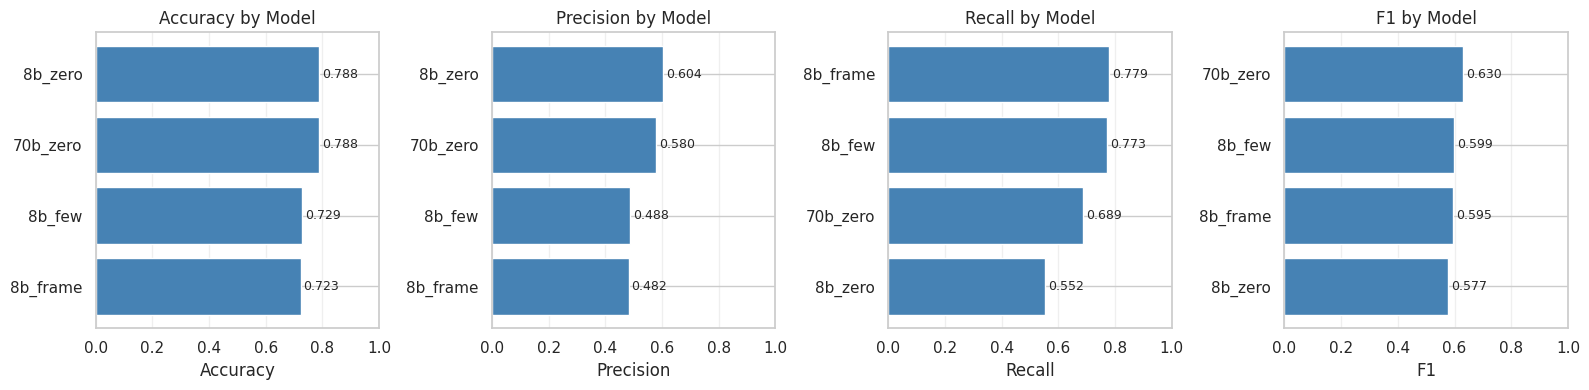


OVERALL RANKING (Average of Accuracy, Precision, Recall, F1)


,experiment,accuracy,precision,recall,f1,avg_score
3,70b_zero,0.788156,0.579845,0.688766,0.629630,0.671599
1,8b_few,0.728936,0.488372,0.773481,0.598717,0.647376
2,8b_frame,0.723158,0.481777,0.779006,0.595355,0.644824
0,8b_zero,0.788156,0.603622,0.552486,0.576923,0.630297



🏆 Best Model: 70b_zero
   F1-Score: 0.6296
   Accuracy: 0.7882
   Precision: 0.5798
   Recall: 0.6888


In [38]:
# Model Ranking by F1 Score (Conspiracy Classification)
if not metrics_df.empty:
    consp_metrics = metrics_df.copy()
    consp_metrics = consp_metrics.sort_values('f1', ascending=False)
    
    print("=" * 80)
    print("MODEL RANKING BY F1-SCORE (CONSPIRACY CLASSIFICATION)")
    print("=" * 80)
    display(consp_metrics[['experiment', 'accuracy', 'precision', 'recall', 'f1', 'n']])
    
    # Visualization
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1']
    for idx, metric in enumerate(metrics_to_plot):
        ax = axes[idx]
        sorted_data = consp_metrics.sort_values(metric, ascending=True)
        ax.barh(sorted_data['experiment'], sorted_data[metric], color='steelblue')
        ax.set_xlabel(metric.capitalize())
        ax.set_title(f'{metric.capitalize()} by Model')
        ax.set_xlim(0, 1)
        ax.grid(axis='x', alpha=0.3)
        
        # Add value labels
        for i, v in enumerate(sorted_data[metric]):
            ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    # Overall ranking (average of all metrics)
    consp_metrics['avg_score'] = (
        consp_metrics['accuracy'] + 
        consp_metrics['precision'] + 
        consp_metrics['recall'] + 
        consp_metrics['f1']
    ) / 4
    
    print("\n" + "=" * 80)
    print("OVERALL RANKING (Average of Accuracy, Precision, Recall, F1)")
    print("=" * 80)
    overall_rank = consp_metrics.sort_values('avg_score', ascending=False)
    display(overall_rank[['experiment', 'accuracy', 'precision', 'recall', 'f1', 'avg_score']])
    
    # Best model
    best_model = overall_rank.iloc[0]
    print(f"\n🏆 Best Model: {best_model['experiment']}")
    print(f"   F1-Score: {best_model['f1']:.4f}")
    print(f"   Accuracy: {best_model['accuracy']:.4f}")
    print(f"   Precision: {best_model['precision']:.4f}")
    print(f"   Recall: {best_model['recall']:.4f}")
else:
    print("No metrics available for ranking.")


## 6. Error Analysis (Conspiracy Classification)

Examine disagreement patterns between models and human annotations for conspiracy classification.


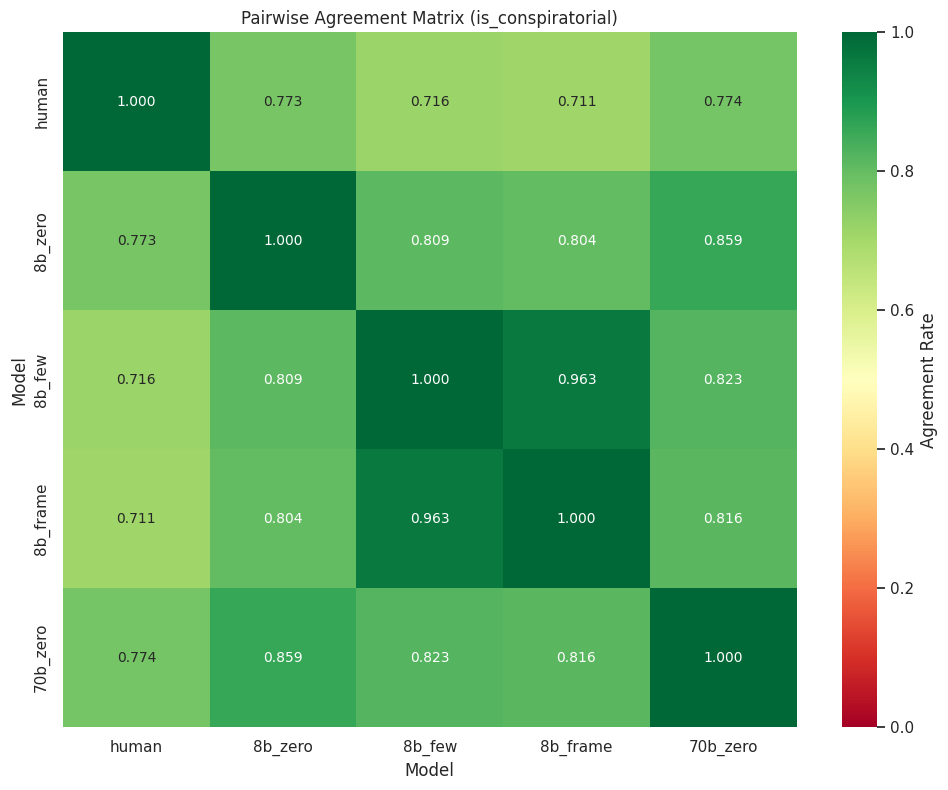

Agreement computed over 2,077 common text_ids


In [ ]:
# Error Analysis: Agreement Matrix
# Compare how often models agree/disagree with each other and with human

if 'agg' in globals() and agg is not None:
    # Build agreement matrix
    agreement_data = []
    
    # Add human predictions
    human_preds = agg.set_index('text_id')['conspiracy_mv'].to_dict()
    
    # Get all model predictions
    model_preds = {}
    for name, df in experiments.items():
        if 'is_conspiratorial' in df.columns and 'text_id' in df.columns:
            model_preds[name] = df.set_index('text_id')['is_conspiratorial'].to_dict()
    
    # Get common text_ids
    all_text_ids = set(agg['text_id'].unique())
    for name in model_preds:
        all_text_ids = all_text_ids.intersection(set(model_preds[name].keys()))
    
    # Compute pairwise agreement
    all_models = ['human'] + list(model_preds.keys())
    agreement_matrix = np.zeros((len(all_models), len(all_models)))
    
    for i, model1 in enumerate(all_models):
        for j, model2 in enumerate(all_models):
            if i == j:
                agreement_matrix[i, j] = 1.0
            else:
                if model1 == 'human':
                    pred1 = {tid: human_preds.get(tid, False) for tid in all_text_ids}
                else:
                    pred1 = {tid: model_preds[model1].get(tid, False) for tid in all_text_ids}
                
                if model2 == 'human':
                    pred2 = {tid: human_preds.get(tid, False) for tid in all_text_ids}
                else:
                    pred2 = {tid: model_preds[model2].get(tid, False) for tid in all_text_ids}
                
                # Compute agreement
                agreements = sum(1 for tid in all_text_ids if pred1[tid] == pred2[tid])
                agreement_matrix[i, j] = agreements / len(all_text_ids) if all_text_ids else 0
    
    # Visualize
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        agreement_matrix,
        annot=True,
        fmt='.3f',
        cmap='RdYlGn',
        vmin=0,
        vmax=1,
        xticklabels=all_models,
        yticklabels=all_models,
        cbar_kws={'label': 'Agreement Rate'}
    )
    plt.title('Pairwise Agreement Matrix (Conspiracy Classification)')
    plt.xlabel('Model')
    plt.ylabel('Model')
    plt.tight_layout()
    plt.show()
    
    print(f"Agreement computed over {len(all_text_ids):,} common text_ids")
else:
    print("Human annotations not available for error analysis.")


## 7. Key Insights & Summary

Summary of findings and recommendations.


In [32]:
# Summary Statistics
print("=" * 80)
print("EXPERIMENT SUMMARY")
print("=" * 80)

if not metrics_df.empty:
    consp_metrics = metrics_df.copy()
    
    print(f"\n📊 Dataset: {len(agg):,} unique texts")
    print(f"📊 Models analyzed: {len(experiments)}/{len(model_files)}")
    if 'missing_models' in globals() and missing_models:
        print(f"⚠ Models still running: {len(missing_models)}")
        for _, name in missing_models:
            print(f"   - {name}")
    
    print("\n🏆 Top 3 Models by F1-Score (Conspiracy Classification):")
    top3 = consp_metrics.nlargest(3, 'f1')
    for idx, (_, row) in enumerate(top3.iterrows(), 1):
        print(f"   {idx}. {row['experiment']:12s} - F1: {row['f1']:.4f}, Acc: {row['accuracy']:.4f}, P: {row['precision']:.4f}, R: {row['recall']:.4f}")
    
    print("\n📈 Performance Range (Conspiracy Classification):")
    print(f"   F1-Score:     {consp_metrics['f1'].min():.4f} - {consp_metrics['f1'].max():.4f} (mean: {consp_metrics['f1'].mean():.4f})")
    print(f"   Accuracy:     {consp_metrics['accuracy'].min():.4f} - {consp_metrics['accuracy'].max():.4f} (mean: {consp_metrics['accuracy'].mean():.4f})")
    print(f"   Precision:   {consp_metrics['precision'].min():.4f} - {consp_metrics['precision'].max():.4f} (mean: {consp_metrics['precision'].mean():.4f})")
    print(f"   Recall:       {consp_metrics['recall'].min():.4f} - {consp_metrics['recall'].max():.4f} (mean: {consp_metrics['recall'].mean():.4f})")
    
    # Model size comparison
    print("\n🔍 Model Size Comparison:")
    size_8b = consp_metrics[consp_metrics['experiment'].str.startswith('8b')]
    size_70b = consp_metrics[consp_metrics['experiment'].str.startswith('70b')]
    if not size_8b.empty and not size_70b.empty:
        print(f"   8B Models - Avg F1: {size_8b['f1'].mean():.4f}")
        print(f"   70B Models - Avg F1: {size_70b['f1'].mean():.4f}")
    
    # Prompt type comparison
    print("\n🔍 Prompt Type Comparison:")
    for ptype in ['zero', 'few', 'frame']:
        ptype_models = consp_metrics[consp_metrics['experiment'].str.contains(ptype)]
        if not ptype_models.empty:
            print(f"   {ptype:8s} - Avg F1: {ptype_models['f1'].mean():.4f} (n={len(ptype_models)})")
    
    print("\n" + "=" * 80)
    print("✓ Analysis complete!")
    print("=" * 80)
else:
    print("No metrics available for summary.")


EXPERIMENT SUMMARY

📊 Dataset: 2,077 unique texts
📊 Models analyzed: 4/6
⚠ Models still running: 2
   - 70B Few-Shot
   - 70B Frame-Guided

🏆 Top 3 Models by F1-Score (Conspiracy Classification):
   1. 70b_zero     - F1: 0.6296, Acc: 0.7882, P: 0.5798, R: 0.6888
   2. 8b_few       - F1: 0.5987, Acc: 0.7289, P: 0.4884, R: 0.7735
   3. 8b_frame     - F1: 0.5954, Acc: 0.7232, P: 0.4818, R: 0.7790

📈 Performance Range (Conspiracy Classification):
   F1-Score:     0.5769 - 0.6296 (mean: 0.6002)
   Accuracy:     0.7232 - 0.7882 (mean: 0.7571)
   Precision:   0.4818 - 0.6036 (mean: 0.5384)
   Recall:       0.5525 - 0.7790 (mean: 0.6984)

🔍 Model Size Comparison:
   8B Models - Avg F1: 0.5903
   70B Models - Avg F1: 0.6296

🔍 Prompt Type Comparison:
   zero     - Avg F1: 0.6033 (n=2)
   few      - Avg F1: 0.5987 (n=1)
   frame    - Avg F1: 0.5954 (n=1)

✓ Analysis complete!
